In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_csv("./dataset/WOD_1931-2025.csv")

C:\Users\simra\AppData\Local\Temp\ipykernel_6904\3781959764.py:2: DtypeWarning: Columns (19,22,31,32,34,35,38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("./dataset/WOD_1931-2025.csv")


In [3]:
df.sample(5)

,ID,Source,OrgID,X,Y,Lat,Lon,Day,Month,Year,...,DSRNoon,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,NoRain3,SOI,ENSO
64886,WOD32954,FENZ,F0911632,1569384.0,5179025.0,-43.541094,172.621040,20,2,2011,...,2.698572,0.0,0.0,0.0,0.0,6.0,12.0,16.0,22.3,La Nina
119763,WOD119780,FENZ,F4176470,1793025.0,5819963.0,-37.747292,175.190897,23,3,2025,...,9.953026,0.0,0.0,0.0,0.2,56.0,60.0,78.0,10.0,Neutral
102880,WOD73341,FENZ,F2904393,1780016.0,5875707.0,-37.247804,175.029687,11,12,2019,...,0.169538,0.0,2.5,2.5,7.0,0.0,2.0,8.0,-5.5,Neutral
36594,WOD88127,FENZ,M089867,1576557.0,5182498.0,-43.510083,172.709975,15,4,2000,...,1.359119,0.0,0.0,0.0,0.0,5.0,6.0,7.0,16.8,La Nina
81657,WOD51466,FENZ,F1763270,1906549.0,5601922.0,-39.677548,176.574072,10,1,2015,...,8.987411,0.0,0.0,0.0,0.0,23.0,24.0,26.0,-7.8,Neutral


In [4]:
df.columns

Index(['ID', 'Source', 'OrgID', 'X', 'Y', 'Lat', 'Lon', 'Day', 'Month', 'Year',
       ...
       'DSRNoon', 'PrecipNoon', 'Precip24hr', 'Precip48hr', 'Precip72hr',
       'NoRain1', 'NoRain2', 'NoRain3', 'SOI', 'ENSO'],
      dtype='object', length=109)

In [5]:
# Useful Features
features = [
    "Temp", "RH", "WS", "WD",
    "PrecipNoon", "Precip24hr", "Precip48hr", "Precip72hr",
    "NoRain1", "NoRain2", "NoRain3",
    "FFMC", "FFMCNoon",
    "ISI", "ISINoon",
    "FWI", "FWINoon",
    "DMCNoon", "DCNoon", "BUINoon", "DSRNoon",
    "FuelType", "FuelClass", "LandCvr",
    "Elev", "Slope", "AspectDeg", "Landform",
    "Lat", "Lon", "FENZDist", "ClimZnName",
    "Month", "Hour", "Day", "Season", "Year",
    "SOI", "ENSO"
]

# Target
target = "AreaHa"

In [6]:
# Extract only required columns
df = df[features + [target]]

In [7]:
df.sample(5)

,Temp,RH,WS,WD,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,...,FENZDist,ClimZnName,Month,Hour,Day,Season,Year,SOI,ENSO,AreaHa
123215,12.9,52.0,-9999.0,-9999.0,0.0,0.0,11.2,11.2,62.0,70.0,...,Mid-South Canterbury,Mount Somers (HV),9,8.0,2,Spring,2024,-1.0,Neutral,0.0500
69761,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,...,Northland,-9999,11,20.0,5,Spring,2012,3.9,Neutral,0.0015
49014,18.9,63.0,2.0,135.0,0.0,0.0,-9999.0,-9999.0,10.0,35.0,...,Manawatu-Whanganui,-9999,2,11.0,13,Summer,1999,8.6,La Nina,0.0000
73768,14.1,99.0,1.2,248.0,0.0,0.5,1.0,26.5,2.0,3.0,...,Auckland,Waharau (AK),5,18.0,8,Autumn,2013,8.4,Neutral,0.0019
26981,20.2,58.0,0.4,359.0,0.0,0.0,0.0,0.0,7.0,8.0,...,Canterbury,Bottle Lake Forest (HV),3,15.0,20,Autumn,2010,-10.6,Neutral,0.0001


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128020 entries, 0 to 128019
Data columns (total 40 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Temp        128020 non-null  float64
 1   RH          128020 non-null  float64
 2   WS          128020 non-null  float64
 3   WD          128020 non-null  float64
 4   PrecipNoon  128020 non-null  float64
 5   Precip24hr  128020 non-null  float64
 6   Precip48hr  128020 non-null  float64
 7   Precip72hr  128020 non-null  float64
 8   NoRain1     128020 non-null  float64
 9   NoRain2     128020 non-null  float64
 10  NoRain3     128020 non-null  float64
 11  FFMC        128020 non-null  float64
 12  FFMCNoon    128020 non-null  float64
 13  ISI         128020 non-null  float64
 14  ISINoon     128020 non-null  float64
 15  FWI         128020 non-null  float64
 16  FWINoon     128020 non-null  float64
 17  DMCNoon     128020 non-null  float64
 18  DCNoon      128020 non-null  float64
 19  BU

In [9]:
df.duplicated().sum()

np.int64(22)

In [10]:
df.drop_duplicates(inplace=True)

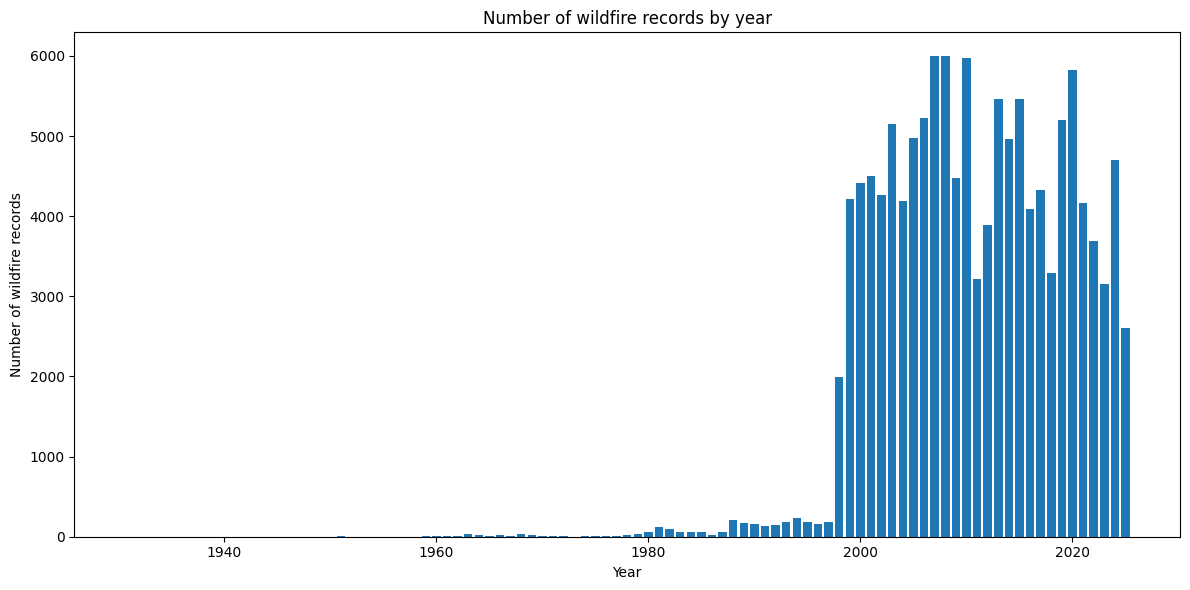

In [11]:
year_counts = df["Year"].value_counts().sort_index()

# Plot
plt.figure(figsize=(12, 6))
plt.bar(year_counts.index, year_counts.values)

plt.xlabel("Year")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records by year")

plt.tight_layout()
plt.show()

In [12]:
year_counts = df[(df["Year"]>1998)]["Year"].value_counts().sort_index()

<BarContainer object of 27 artists>

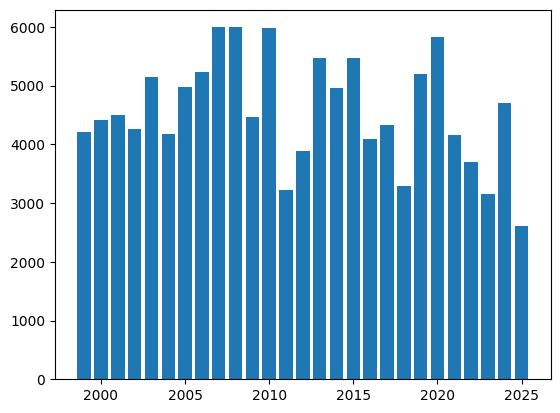

In [13]:
plt.bar(year_counts.index, year_counts.values)

In [14]:
df = df[df["Year"] >= 1998]

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 125385 entries, 0 to 128019
Data columns (total 40 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Temp        125385 non-null  float64
 1   RH          125385 non-null  float64
 2   WS          125385 non-null  float64
 3   WD          125385 non-null  float64
 4   PrecipNoon  125385 non-null  float64
 5   Precip24hr  125385 non-null  float64
 6   Precip48hr  125385 non-null  float64
 7   Precip72hr  125385 non-null  float64
 8   NoRain1     125385 non-null  float64
 9   NoRain2     125385 non-null  float64
 10  NoRain3     125385 non-null  float64
 11  FFMC        125385 non-null  float64
 12  FFMCNoon    125385 non-null  float64
 13  ISI         125385 non-null  float64
 14  ISINoon     125385 non-null  float64
 15  FWI         125385 non-null  float64
 16  FWINoon     125385 non-null  float64
 17  DMCNoon     125385 non-null  float64
 18  DCNoon      125385 non-null  float64
 19  BUINoon

In [16]:
df.describe()

,Temp,RH,WS,WD,PrecipNoon,Precip24hr,Precip48hr,Precip72hr,NoRain1,NoRain2,...,Slope,AspectDeg,Lat,Lon,Month,Hour,Day,Year,SOI,AreaHa
count,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,...,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000,125385.000000
mean,-2767.369181,-2734.778730,-2773.910066,-2713.760266,-2418.687517,-3170.293671,-3557.752755,-3916.847857,-2486.540216,-2508.096862,...,-59.651014,-139.091437,-40.053152,173.953625,6.284205,-214.751095,15.314128,2011.327105,-1.350524,1.156908
std,4487.279559,4510.570581,4480.012702,4596.613838,4282.749752,4653.494038,4788.596843,4883.318422,4332.919762,4348.541234,...,785.895807,1762.204188,3.203456,4.613655,4.027894,1497.271890,8.951285,7.620313,185.449412,39.594530
min,-9999.000000,-9999.000000,-9999.000000,-9999.000000,-9999.000000,-9999.000000,-9999.000000,-9999.000000,-9999.000000,-9999.000000,...,-9999.000000,-9999.000000,-47.211129,-176.609619,1.000000,-9999.000000,1.000000,1998.000000,-9999.000000,-0.000100
25%,-9999.000000,-9999.000000,-9999.000000,-9999.000000,0.000000,-9999.000000,-9999.000000,-9999.000000,0.000000,-9999.000000,...,0.000000,92.593697,-43.345925,172.659673,2.000000,12.000000,7.000000,2005.000000,-5.500000,0.000100
50%,14.400000,57.000000,2.200000,103.000000,0.000000,0.000000,0.000000,0.000000,2.000000,5.000000,...,1.000000,160.308807,-39.594443,174.698698,5.000000,15.000000,15.000000,2011.000000,1.300000,0.000500
75%,19.400000,74.000000,4.300000,248.000000,0.000000,0.000000,0.200000,0.800000,7.000000,13.000000,...,3.000000,252.751434,-37.081293,175.308329,11.000000,18.000000,23.000000,2018.000000,9.400000,0.004000
max,48.000000,100.000000,38.520000,360.000000,208.400000,194.400000,302.000000,326.400000,90.000000,90.000000,...,43.000000,359.737915,-34.159987,178.971857,12.000000,23.000000,31.000000,2025.000000,27.100000,6159.000000


In [17]:
df_selected = df.replace(-9999, np.nan)

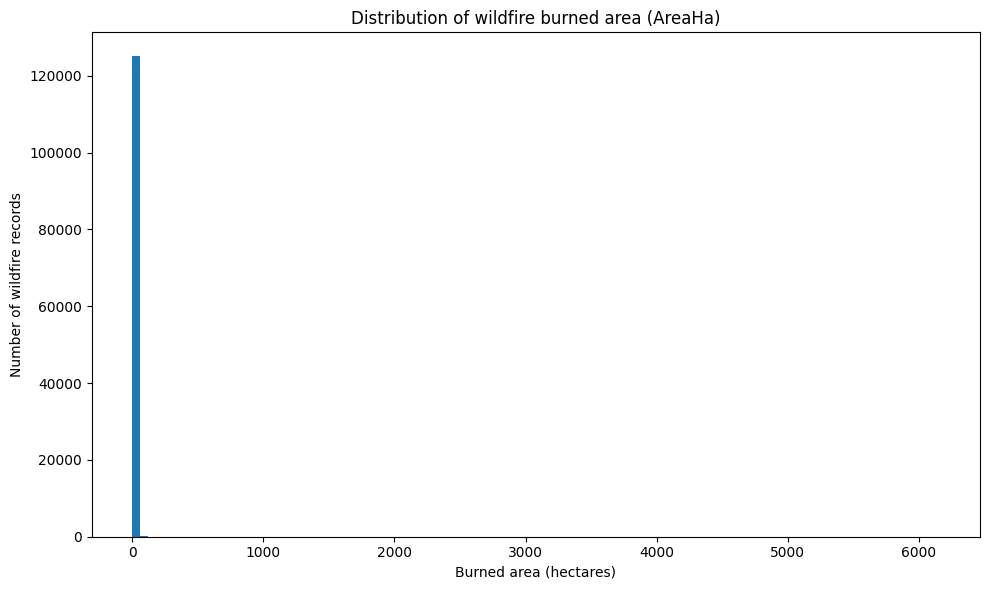

In [18]:
plt.figure(figsize=(10, 6))

plt.hist(df["AreaHa"].dropna(), bins=100)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Distribution of wildfire burned area (AreaHa)")

plt.tight_layout()
plt.show()

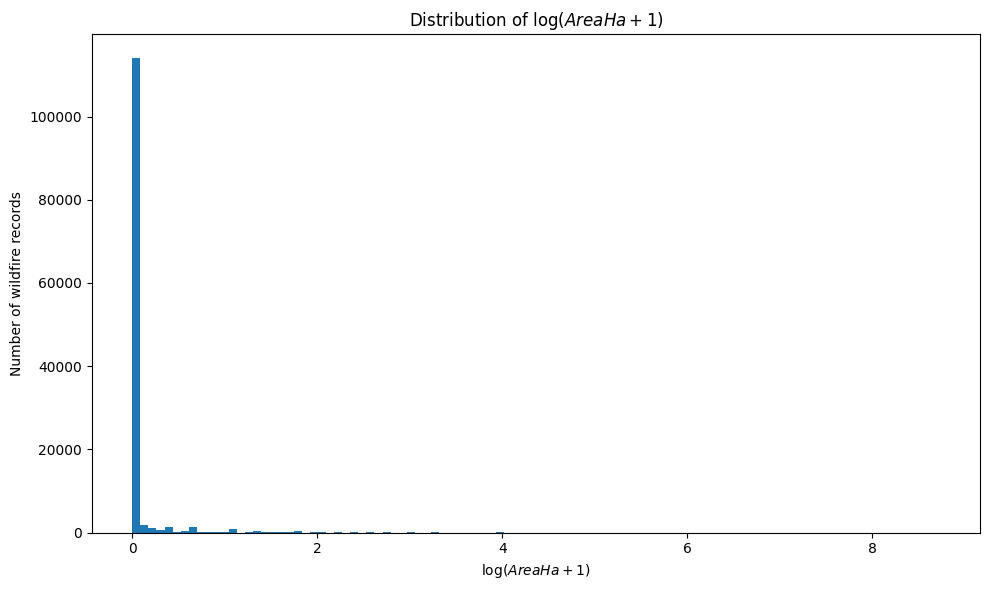

In [19]:
log_area = np.log1p(df["AreaHa"].dropna())

plt.figure(figsize=(10, 6))

plt.hist(log_area, bins=100)

plt.xlabel(r"$\log(AreaHa + 1)$")
plt.ylabel("Number of wildfire records")
plt.title(r"Distribution of $\log(AreaHa + 1)$")

plt.tight_layout()
plt.show()

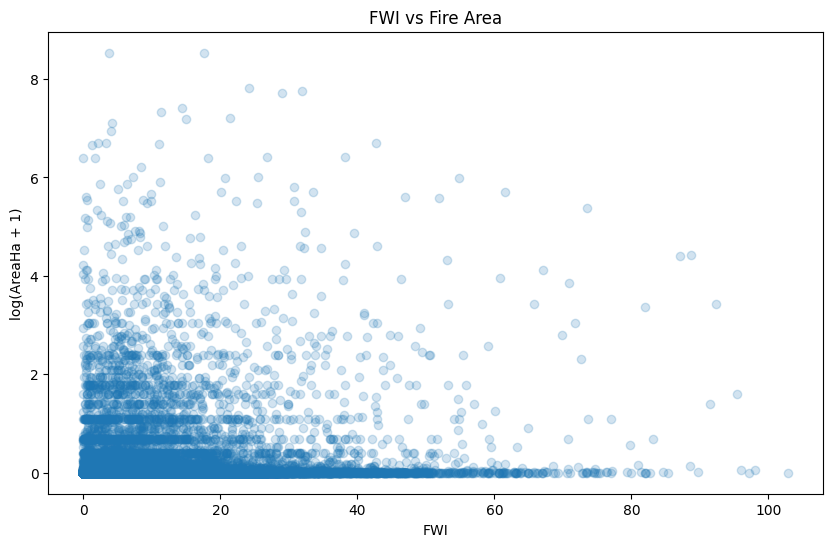

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_selected["FWI"],
    np.log1p(df_selected["AreaHa"]),
    alpha=0.2
)

plt.xlabel("FWI")
plt.ylabel("log(AreaHa + 1)")
plt.title("FWI vs Fire Area")

plt.show()

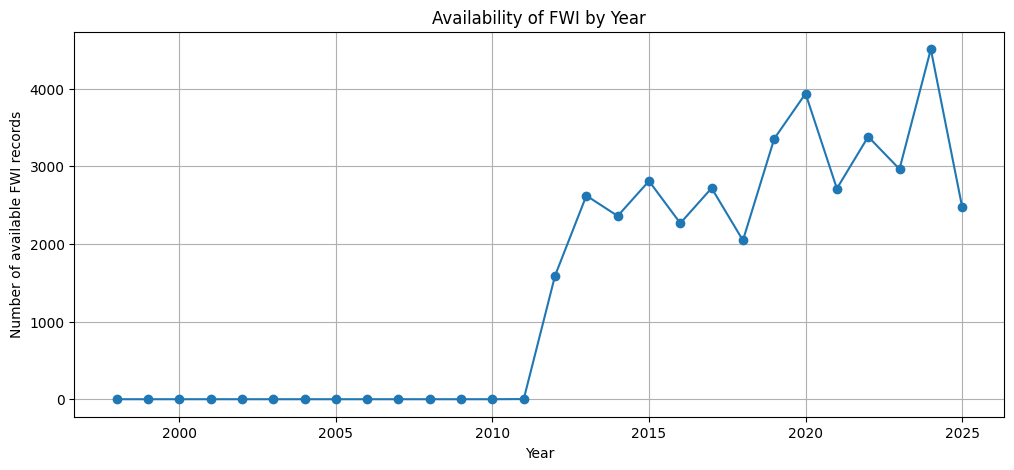

In [25]:
plt.figure(figsize=(12,5))

plt.plot(
    fwi_by_year.index,
    fwi_by_year.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of available FWI records")
plt.title("Availability of FWI by Year")
plt.grid(True)
plt.show()

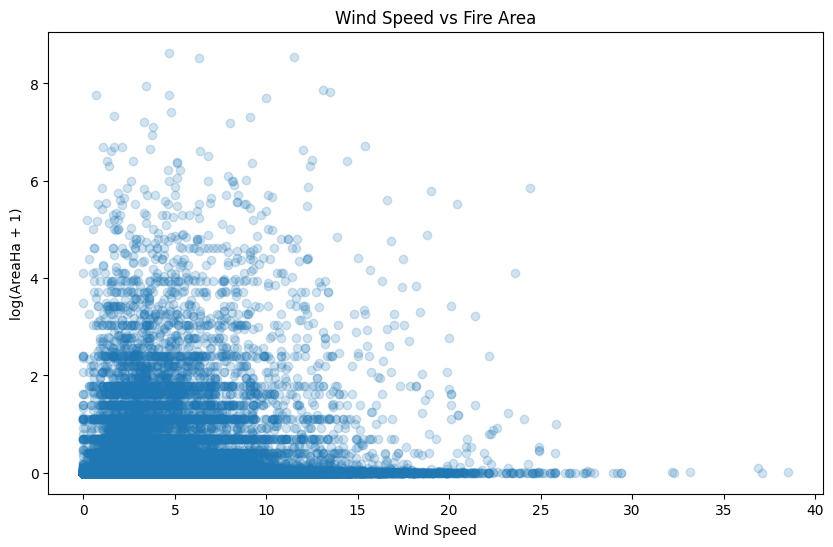

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_selected["WS"],
    np.log1p(df_selected["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Wind Speed")
plt.ylabel("log(AreaHa + 1)")
plt.title("Wind Speed vs Fire Area")
plt.show()

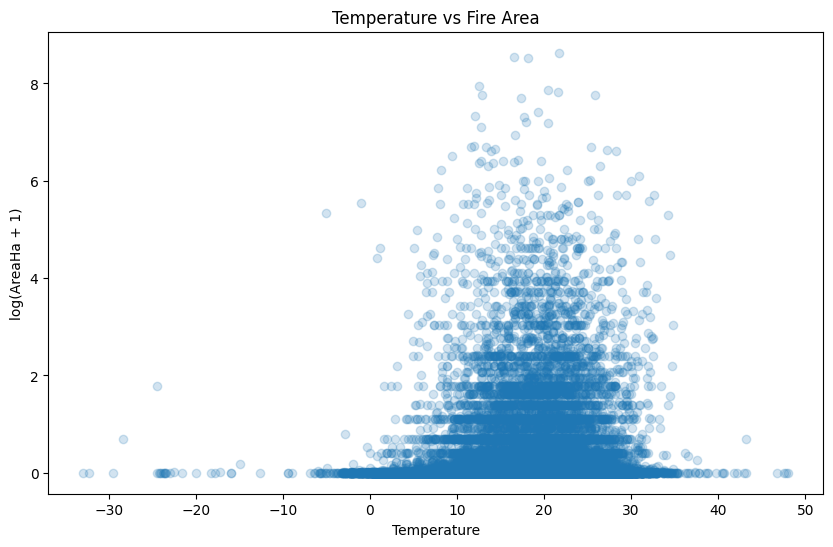

In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_selected["Temp"],
    np.log1p(df_selected["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Temperature")
plt.ylabel("log(AreaHa + 1)")
plt.title("Temperature vs Fire Area")
plt.show()

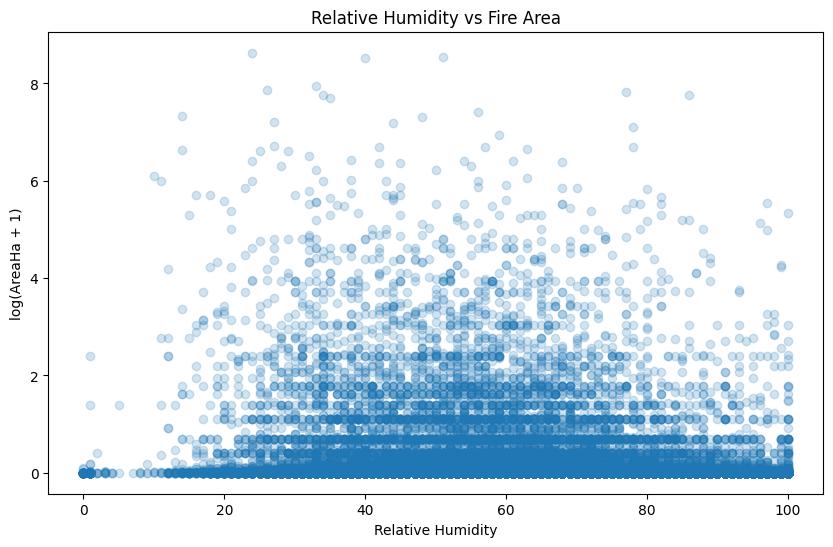

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_selected["RH"],
    np.log1p(df_selected["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Relative Humidity")
plt.ylabel("log(AreaHa + 1)")
plt.title("Relative Humidity vs Fire Area")
plt.show()

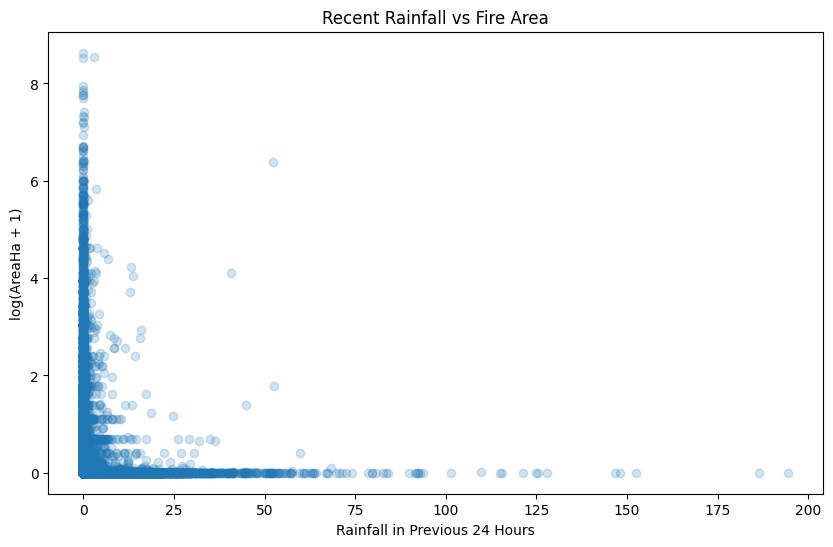

In [30]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_selected["Precip24hr"],
    np.log1p(df_selected["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Rainfall in Previous 24 Hours")
plt.ylabel("log(AreaHa + 1)")
plt.title("Recent Rainfall vs Fire Area")
plt.show()

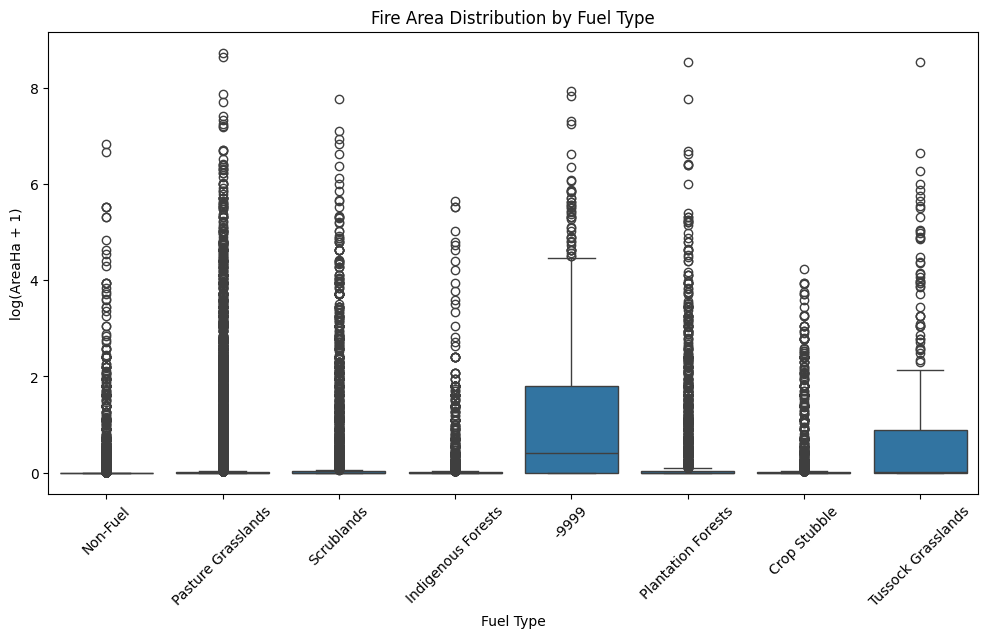

In [31]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_selected,
    x="FuelType",
    y=np.log1p(df_selected["AreaHa"])
)

plt.xlabel("Fuel Type")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Fuel Type")
plt.xticks(rotation=45)
plt.show()

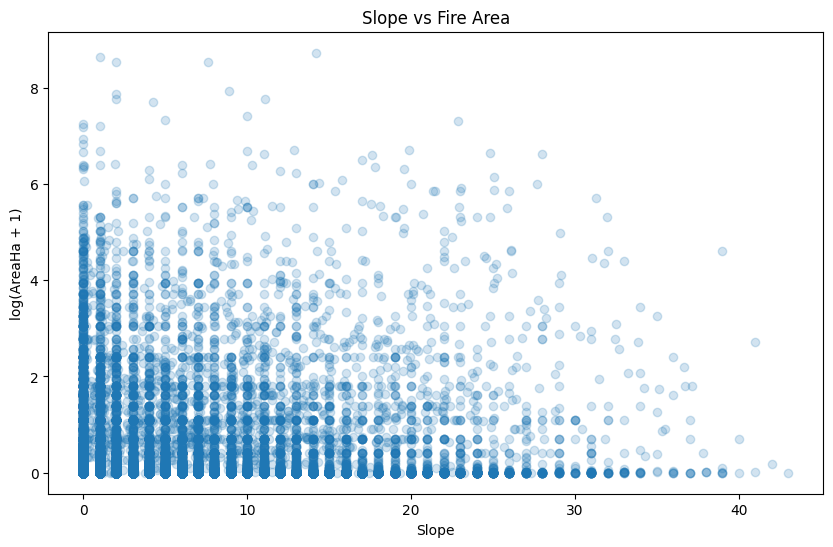

In [32]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_selected["Slope"],
    np.log1p(df_selected["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Slope")
plt.ylabel("log(AreaHa + 1)")
plt.title("Slope vs Fire Area")
plt.show()

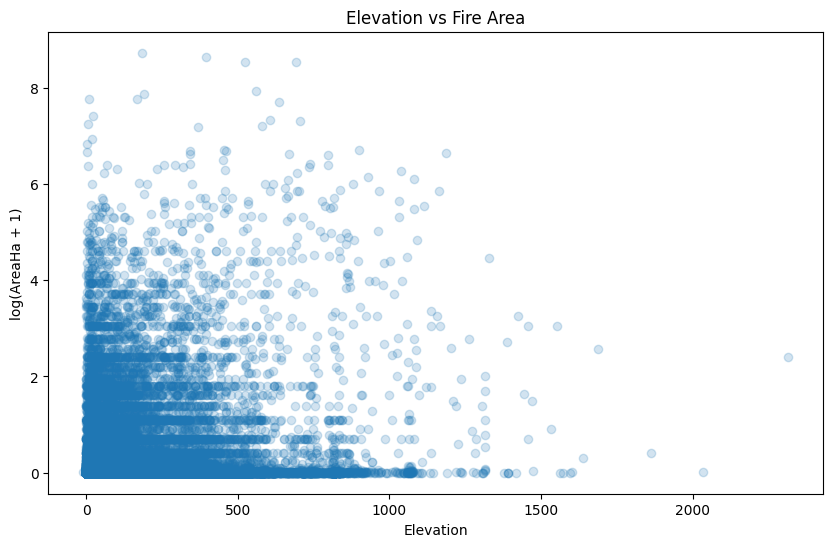

In [33]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_selected["Elev"],
    np.log1p(df_selected["AreaHa"]),
    alpha=0.2
)

plt.xlabel("Elevation")
plt.ylabel("log(AreaHa + 1)")
plt.title("Elevation vs Fire Area")
plt.show()

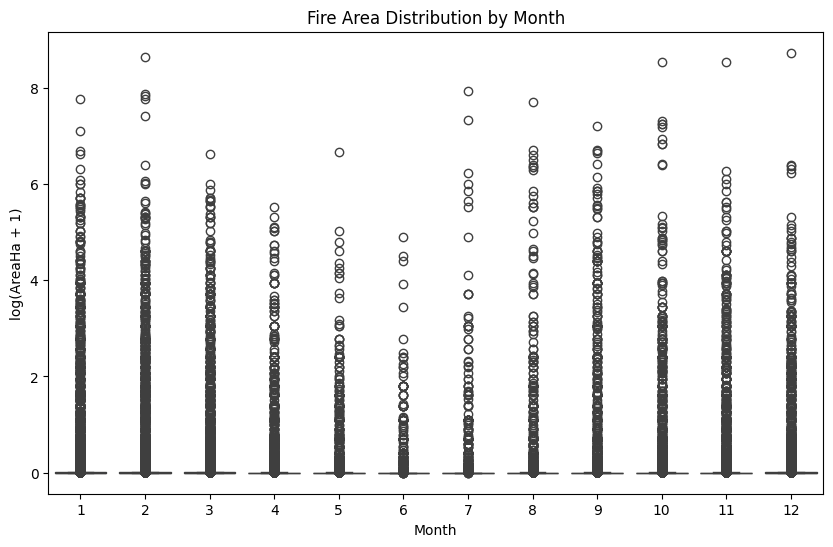

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_selected,
    x="Month",
    y=np.log1p(df_selected["AreaHa"])
)

plt.xlabel("Month")
plt.ylabel("log(AreaHa + 1)")
plt.title("Fire Area Distribution by Month")
plt.show()

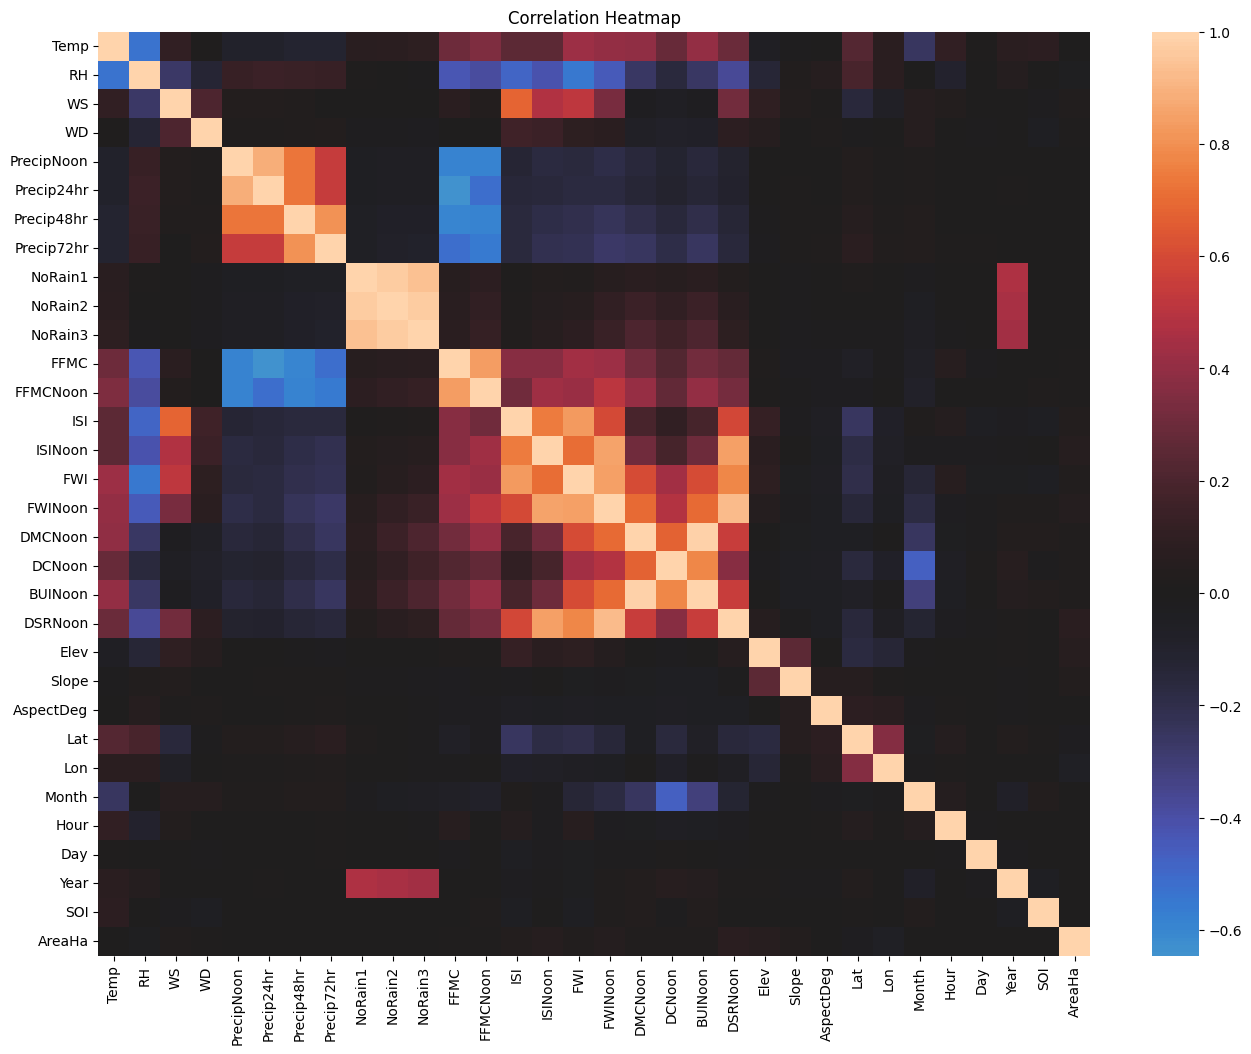

In [35]:
numeric_cols = df_selected.select_dtypes(include="number").columns

plt.figure(figsize=(16, 12))

sns.heatmap(
    df_selected[numeric_cols].corr(),
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

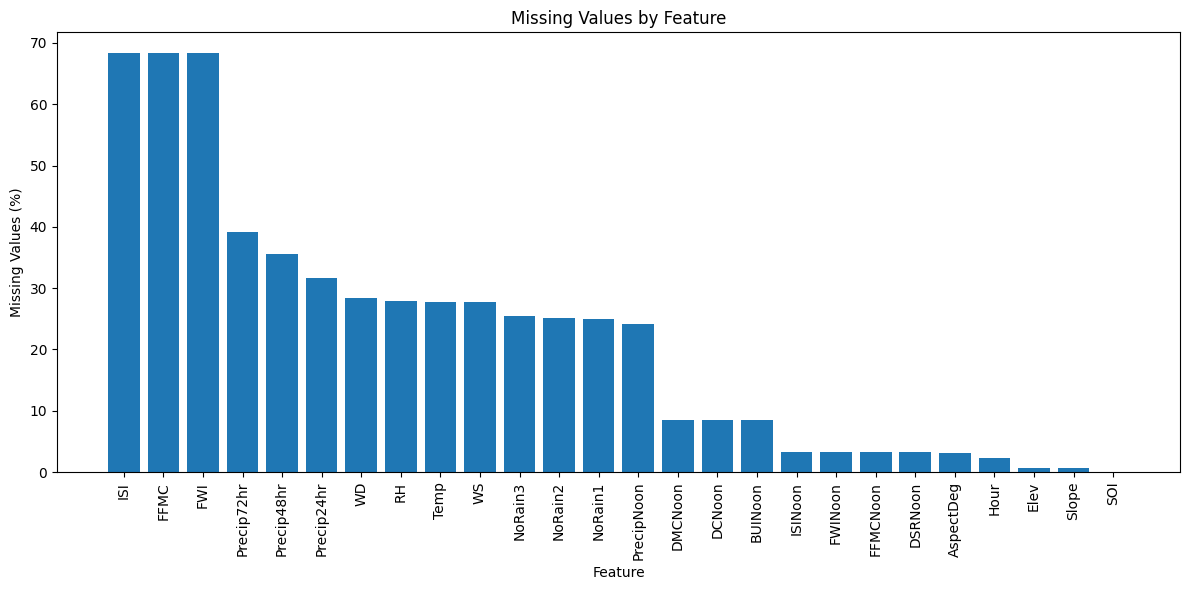

In [36]:
missing = df_selected.isnull().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(12,6))
plt.bar(missing.index, missing.values)

plt.xlabel("Feature")
plt.ylabel("Missing Values (%)")
plt.title("Missing Values by Feature")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

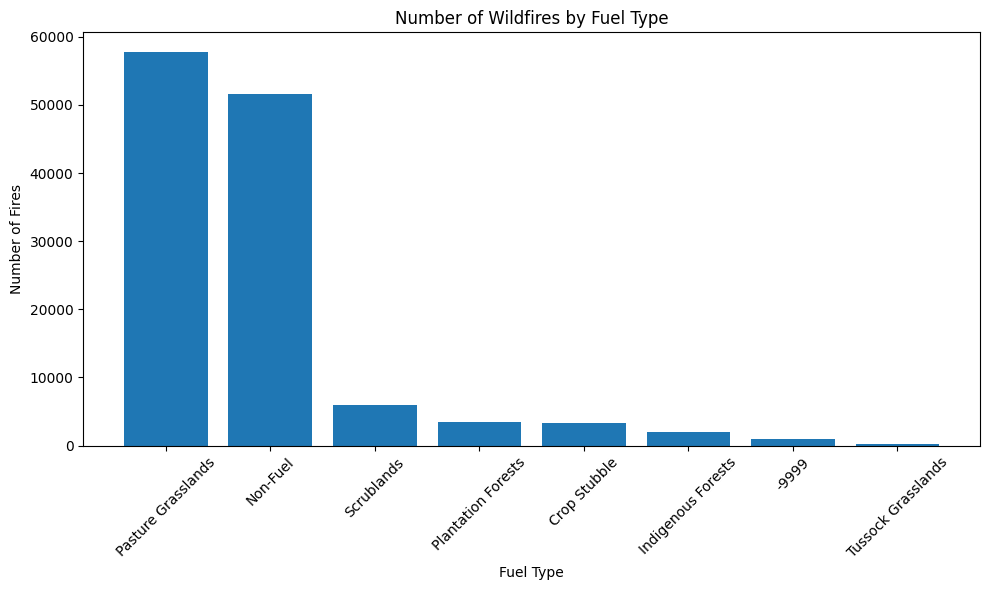

In [37]:
fuel_counts = df_selected["FuelType"].value_counts()

plt.figure(figsize=(10,6))
plt.bar(fuel_counts.index, fuel_counts.values)

plt.xlabel("Fuel Type")
plt.ylabel("Number of Fires")
plt.title("Number of Wildfires by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

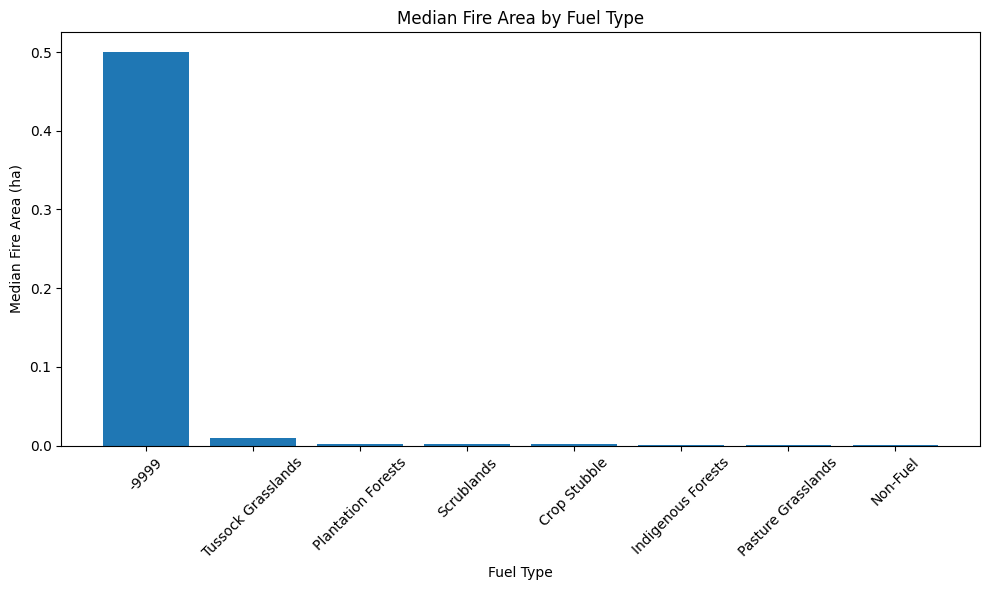

In [38]:
fuel_median = (
    df_selected.groupby("FuelType")["AreaHa"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))
plt.bar(fuel_median.index, fuel_median.values)

plt.xlabel("Fuel Type")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Fuel Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

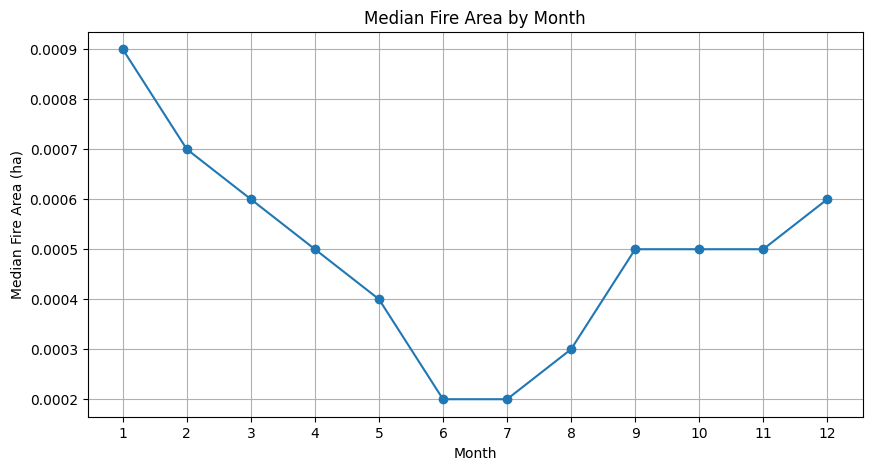

In [39]:
monthly_median = (
    df_selected.groupby("Month")["AreaHa"]
    .median()
)

plt.figure(figsize=(10,5))
plt.plot(
    monthly_median.index,
    monthly_median.values,
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Median Fire Area (ha)")
plt.title("Median Fire Area by Month")
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

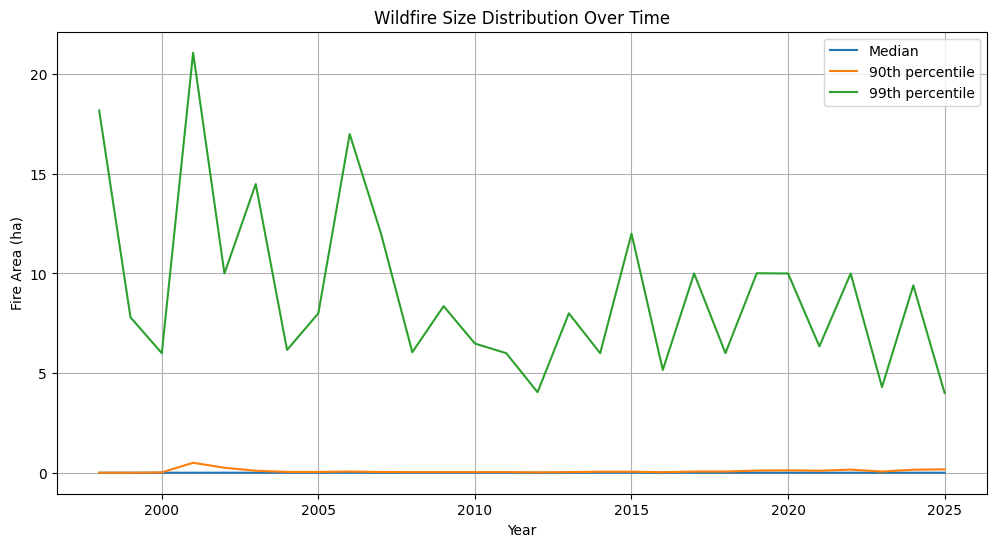

In [40]:
year_area = df_selected.groupby("Year")["AreaHa"].agg(
    median="median",
    p90=lambda x: x.quantile(0.90),
    p99=lambda x: x.quantile(0.99)
)

plt.figure(figsize=(12,6))

plt.plot(year_area.index, year_area["median"], label="Median")
plt.plot(year_area.index, year_area["p90"], label="90th percentile")
plt.plot(year_area.index, year_area["p99"], label="99th percentile")

plt.xlabel("Year")
plt.ylabel("Fire Area (ha)")
plt.title("Wildfire Size Distribution Over Time")
plt.legend()
plt.grid(True)
plt.show()

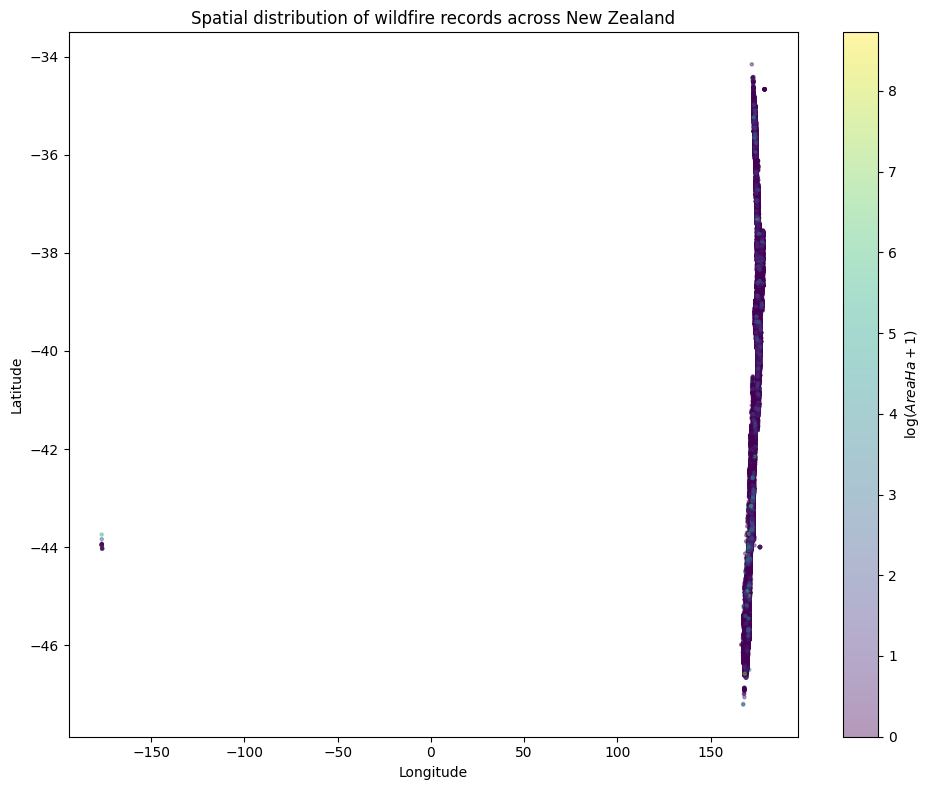

In [47]:
spatial_df = df_selected[
    df_selected["Lon"].notna() &
    df_selected["Lat"].notna() &
    df_selected["AreaHa"].notna()
].copy()

# Log-transform burned area for visualisation
spatial_df["LogArea"] = np.log1p(spatial_df["AreaHa"])

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    spatial_df["Lon"],
    spatial_df["Lat"],
    c=spatial_df["LogArea"],
    s=5,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial distribution of wildfire records across New Zealand")

cbar = plt.colorbar(scatter)
cbar.set_label(r"$\log(AreaHa + 1)$")

plt.tight_layout()
plt.show()

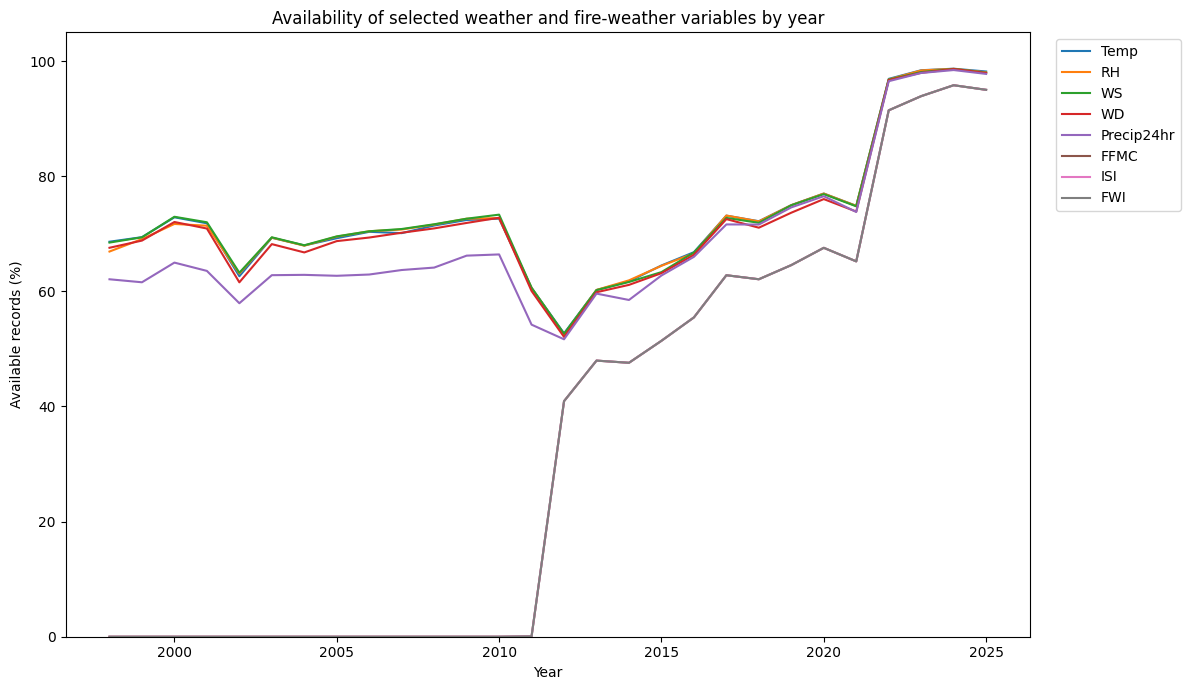

In [44]:
features = [
    "Temp",
    "RH",
    "WS",
    "WD",
    "Precip24hr",
    "FFMC",
    "ISI",
    "FWI"
]

# Calculate percentage of available values for each feature by year
availability = (
    df_selected
    .groupby("Year")[features]
    .apply(lambda x: x.notna().mean() * 100)
)

# Plot
plt.figure(figsize=(12, 7))

for feature in features:
    plt.plot(
        availability.index,
        availability[feature],
        label=feature
    )

plt.xlabel("Year")
plt.ylabel("Available records (%)")
plt.title("Availability of selected weather and fire-weather variables by year")

plt.ylim(0, 105)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

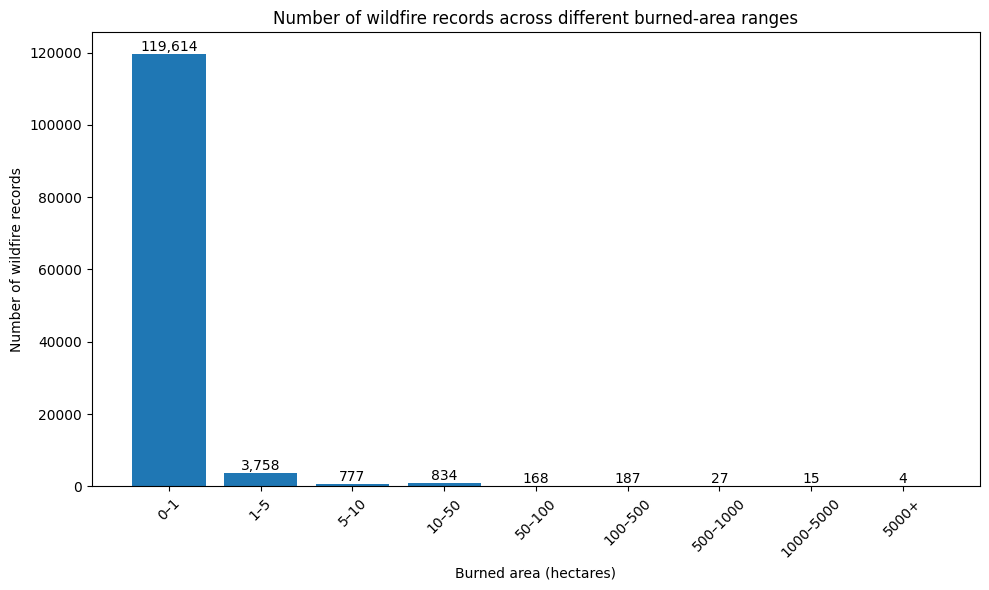

In [45]:
bins = [0, 1, 5, 10, 50, 100, 500, 1000, 5000, float("inf")]
labels = [
    "0–1",
    "1–5",
    "5–10",
    "10–50",
    "50–100",
    "100–500",
    "500–1000",
    "1000–5000",
    "5000+"
]

# Group wildfire records by burned-area range
fire_size_ranges = pd.cut(
    df_selected["AreaHa"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
size_counts = fire_size_ranges.value_counts().sort_index()

# Plot
plt.figure(figsize=(10, 6))

bars = plt.bar(
    size_counts.index,
    size_counts.values
)

plt.xlabel("Burned area (hectares)")
plt.ylabel("Number of wildfire records")
plt.title("Number of wildfire records across different burned-area ranges")

# Add count labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()